<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/04_Regression/notebooks/03_Multiple_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
#Create the dataset
data = {
    "Experience": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Education": [1, 2, 2, 3, 3, 4, 4, 4, 5, 5],
    "Skills": [2, 3, 4, 5, 6, 7, 8, 9, 9, 10],
    "Salary": [3, 5, 7, 10, 12, 15, 17, 19, 22, 25]
}

df = pd.DataFrame(data)

df

,Experience,Education,Skills,Salary
0,1,1,2,3
1,2,2,3,5
2,3,2,4,7
3,4,3,5,10
4,5,3,6,12
5,6,4,7,15
6,7,4,8,17
7,8,4,9,19
8,9,5,9,22
9,10,5,10,25


In [3]:
#Explore the dataset
print("Shape:", df.shape)

print("\nInformation:")
df.info()

print("\nStatistical summary:")
df.describe()

Shape: (10, 4)

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Experience  10 non-null     int64
 1   Education   10 non-null     int64
 2   Skills      10 non-null     int64
 3   Salary      10 non-null     int64
dtypes: int64(4)
memory usage: 452.0 bytes

Statistical summary:


,Experience,Education,Skills,Salary
count,10.00000,10.000000,10.000000,10.000000
mean,5.50000,3.300000,6.300000,13.500000
std,3.02765,1.337494,2.750757,7.367345
min,1.00000,1.000000,2.000000,3.000000
25%,3.25000,2.250000,4.250000,7.750000
50%,5.50000,3.500000,6.500000,13.500000
75%,7.75000,4.000000,8.750000,18.500000
max,10.00000,5.000000,10.000000,25.000000


In [4]:
#Separate features and target
X = df[["Experience", "Education", "Skills"]]

y = df["Salary"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Experience  Education  Skills
0           1          1       2
1           2          2       3
2           3          2       4
3           4          3       5
4           5          3       6

Target:
0     3
1     5
2     7
3    10
4    12
Name: Salary, dtype: int64


In [5]:
#Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8
Testing records: 2


In [6]:
#Create and train the model
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [7]:
#Understand the coefficients
print("Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients

Intercept: 1.2499999999999858


,Feature,Coefficient
0,Experience,3.35
1,Education,0.65
2,Skills,-1.30


In [8]:
#Understand the complete equation
print("Regression Equation:")

print(
    f"Salary = {model.intercept_:.2f}"
    f" + ({model.coef_[0]:.2f} × Experience)"
    f" + ({model.coef_[1]:.2f} × Education)"
    f" + ({model.coef_[2]:.2f} × Skills)"
)

Regression Equation:
Salary = 1.25 + (3.35 × Experience) + (0.65 × Education) + (-1.30 × Skills)


In [9]:
#Make predictions
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})

comparison

,Actual Salary,Predicted Salary
0,22,22.95
1,5,5.35


In [10]:
#Evaluate the model
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.6499999999999977
MSE: 0.5125000000000001
RMSE: 0.7158910531638177
R2 Score: 0.9929065743944636


In [11]:
#Predict salary for a new employee
new_employee = pd.DataFrame({
    "Experience": [6],
    "Education": [4],
    "Skills": [8]
})

predicted_salary = model.predict(new_employee)

print(
    "Predicted Salary:",
    predicted_salary[0],
    "Lakh"
)

Predicted Salary: 13.549999999999999 Lakh


            Experience  Education    Skills    Salary
Experience    1.000000   0.974066  0.993930  0.998746
Education     0.974066   1.000000  0.969435  0.975373
Skills        0.993930   0.969435  1.000000  0.989627
Salary        0.998746   0.975373  0.989627  1.000000


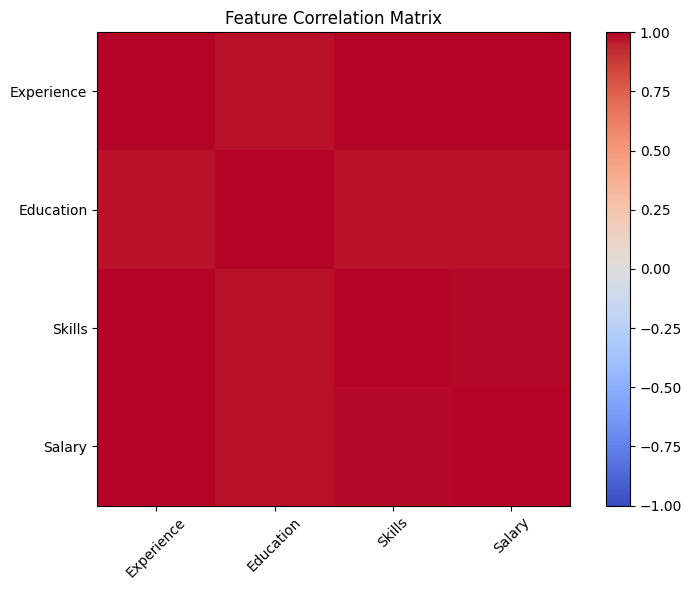

In [12]:
#Feature correlation
correlation = df.corr()

print(correlation)

#Visualize the correlation matrix:
plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()